# Site figures (results 1.3, 1.3.1, 1.4)

Figures in the style of Muir et al. (2024): **(a)** the site on an aerial with the extracted edges of all six scenarios on both satellites (colour = scenario, solid = Sentinel-2, dotted = Landsat 8) and the NZCCD lines white dashed; **(b), (c)** violins of the transect errors for all six scenarios, Sentinel-2 and Landsat 8, in one frame, with each scenario's median distance (η<sub>dist</sub>, as Muir et al.) beside its name; **(d), (e)** close-ups of the edges against NZCCD (white dashed), marked D and E on the map.

Reads only saved outputs (the run folders' veglines shapefiles, `errors_all.csv` and transect shapefiles from the comparison cells, the NZCCD lines); nothing is rerun. Figures are saved (overwritten) as PNG and PDF in `Data/Extra_analyses/site_figures`.

Run the settings cell, the functions cell, then any site cell. **Once only:** run `%pip install contextily matplotlib-map-utils` in a cell and restart the kernel (the aerial; the scale bars and north arrows).

**Close-ups** (`zooms`, two entries): `('frac', f)` = a point f of the way along the coast from south (0) to north (1), or `('frac', f, dx, dy)` shifted dx m east and dy m north; `('latlon', lat, lon)` (e.g. right-click in Google Maps to copy them); `('transect', id)`; `'best'` / `'worst'` = the most / least accurate stretch. The cell prints where each close-up landed.
**Map extent:** all the shown edges plus `pad` metres; or set `extent_latlon=(south, west, north, east)` to choose it.

In [43]:
# ---------------- Settings (shared by every figure) ----------------
import os
DATA = os.path.join(os.getcwd(), 'Data')                       # run from the COASTGUARD-master folder
NZCCD_DIR = os.path.join(DATA, 'NZCCD_Lines_Pakiri_Muriwai')
OUT_DIR = os.path.join(DATA, 'Extra_analyses', 'site_figures')  # figures are overwritten on every run

# Aerial basemap. LINZ: open https://basemaps.linz.govt.nz, choose Aerial, copy the "XYZ" tile URL from the
# menu (it contains {z}/{x}/{y} and ?api=...) and paste it here. Left empty, Esri World Imagery is used.
BASEMAP_URL = ''
ATTRIBUTION = 'Aerial imagery: LINZ Basemaps (CC BY 4.0)' if BASEMAP_URL else 'Imagery: Esri World Imagery'
ZOOM_ADJUST = 0      # +1 = sharper (more, smaller tiles) basemap; -1 = coarser and faster
DPI = 300
WITHIN = 10          # m, accuracy target, shaded in panel (b)


In [44]:
# ---------------- Functions: main site figures (Pakiri, Muriwai) and shared map code ----------------
import glob
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib import patheffects
from matplotlib import cbook, mlab
from shapely.ops import unary_union
from IPython.display import Image, display
try:
    from matplotlib_map_utils import north_arrow as mmu_north_arrow, scale_bar as mmu_scale_bar
except ImportError:
    mmu_north_arrow = mmu_scale_bar = None
    print('matplotlib-map-utils is not installed, so simple drawn scale bars are used: run  '
          '%pip install matplotlib-map-utils  then restart the kernel')
try:
    import contextily as ctx
except ImportError:
    ctx = None
    print('contextily is not installed, so maps have no aerial: run  %pip install contextily  then restart the kernel')

CRS = 'EPSG:2193'
SCEN_RUN = {'default_WP': 'Default (WP)', 'default_local': 'Default (local)', 'NZ_WP': 'NZ (WP)',
            'NZ_local': 'NZ (local)', 'NZsparse_WP': 'NZsparse (WP)', 'NZsparse_local': 'NZsparse (local)'}  # as in errors_all.csv
SCEN_LABEL = {'default_WP': 'VedgeSat, Weighted Peaks', 'default_local': 'VedgeSat, local threshold',
              'NZ_WP': 'NZ, Weighted Peaks', 'NZ_local': 'NZ, local threshold',
              'NZsparse_WP': 'NZsparse, Weighted Peaks', 'NZsparse_local': 'NZsparse, local threshold'}
SCEN_COLOUR = {'default_WP': '#1a0b2e', 'default_local': '#1b068d',     # VedgeSat: black-purple, deep purple
               'NZ_WP': '#1560bd', 'NZ_local': '#8f99fb',               # NZ: denim blue, periwinkle
               'NZsparse_WP': '#cc5500', 'NZsparse_local': '#fca636'}   # NZsparse: burnt orange, orange
SAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8'}
SCEN_ORDER = list(SCEN_RUN)
SCEN_SHORT = {'default_WP': 'VedgeSat WP', 'default_local': 'VedgeSat local', 'NZ_WP': 'NZ WP',
              'NZ_local': 'NZ local', 'NZsparse_WP': 'NZsparse WP', 'NZsparse_local': 'NZsparse local'}


def veglines_file(run):
    hits = [f for f in glob.glob(os.path.join(DATA, run, 'lines', '*.shp'))
            if 'vegline' in os.path.basename(f).lower() and 'water' not in os.path.basename(f).lower()]
    return sorted(hits, key=len)[0] if hits else None


SAT_LS = {'S2': '-', 'L8': (0, (2.2, 1.2))}       # map line style per satellite: S2 solid, L8 dotted-dashed
ETA = r'$\eta_{dist}$'                            # median distance, symbol as in Muir et al. (2024)
signed = lambda v: f'{v:+.1f}'.replace('-', '\u2212')


def build_layers(cfg, E):
    """One layer per extracted edge (image x scenario x satellite), styled by scenario (colour) and satellite
    (line style); all images of a scenario and satellite share one symbol."""
    sats = cfg.get('map_sats', ['S2', 'L8'])
    scens = cfg.get('map_scenarios', SCEN_ORDER)
    layers = []
    for sat in sats:
        for scen in scens:
            for nz in cfg['nzccd']:
                run = f"{cfg['tag']}_{cfg['site']}_{nz}_{scen}"
                f = veglines_file(run)
                if f is None:
                    print(f'No veglines shapefile for {run}: skipped')
                    continue
                g = gpd.read_file(f).to_crs(CRS)
                g = g[g.geometry.notna() & ~g.geometry.is_empty]
                g = g[g.satname == sat].copy()
                g['day'] = g['dates'].astype(str).str[:10]
                for day, gg in g.groupby('day'):
                    e = E[(E.nzccd_date == nz) & (E.run == SCEN_RUN[scen]) & (E.satname == sat) & (E.date == day)]
                    layers.append(dict(sat=sat, scen=scen, date=day, nz=nz, geom=unary_union(list(gg.geometry)),
                                       err=e.error_m.values, tids=e.TransectID.values,
                                       colour=SCEN_COLOUR[scen], ls=SAT_LS[sat]))
    if not layers:
        raise ValueError('No edges found: check tag, site, scenario names and the run folders in Data')
    return layers


def nzccd_colours(cfg, layers):
    """NZCCD lines: white dashed with a dark outline."""
    return {nz: 'white' for nz in cfg['nzccd']}


def nice_length(width_m):
    target = width_m / 4
    p = 10 ** np.floor(np.log10(target))
    return int(max(m * p for m in (1, 2, 5) if m * p <= target))


HALO = [patheffects.withStroke(linewidth=2.2, foreground='black', alpha=0.7)]


def simple_scale_bar(ax, frac=(0.06, 0.05)):
    """Scale line with end and middle ticks and white labels (like Esri's 'Scale Line 1 Metric'), plus a north
    arrow above it."""
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    L = nice_length(x1 - x0)
    x, y = x0 + frac[0] * (x1 - x0), y0 + frac[1] * (y1 - y0)
    t = 0.012 * (y1 - y0)                                     # tick height
    kw = dict(color='white', lw=1.3, zorder=11, solid_capstyle='butt', path_effects=HALO)
    ax.plot([x, x + L], [y, y], **kw)
    for k, xt in enumerate([x, x + L / 2, x + L]):
        ax.plot([xt, xt], [y, y + t], **kw)
        lab = f'{(L * k / 2):g}' + (' m' if k == 2 else '')
        ax.text(xt, y + 1.6 * t, lab, color='white', fontsize=7, ha='center',
                va='bottom', zorder=12, path_effects=HALO)
    # north arrow above the scale line (NZTM grid north is within a degree of true north here)
    ax_ = x + 0.04 * (x1 - x0)
    ay0, ay1 = y + 0.07 * (y1 - y0), y + 0.13 * (y1 - y0)
    ax.annotate('', xy=(ax_, ay1), xytext=(ax_, ay0), zorder=12,
                arrowprops=dict(arrowstyle='-|>,head_width=0.3,head_length=0.6', color='white', lw=1.4,
                                path_effects=HALO))
    ax.text(ax_, ay1 + 0.008 * (y1 - y0), 'N', color='white', fontsize=8, fontweight='bold', ha='center',
            va='bottom', zorder=12, path_effects=HALO)


def scale_and_north(ax, max_m):
    """Scale bar (bottom left, Esri 'scale line' style, 0 / half / max_m metres) with the north arrow above it,
    both from matplotlib-map-utils and white so they read on the aerial. Falls back to simple drawn versions if the
    package is missing or fails."""
    if mmu_scale_bar is None:
        return simple_scale_bar(ax)
    try:
        mmu_scale_bar(ax=ax, location='lower left', style='ticks',
                      bar={'projection': 2193, 'unit': 'm', 'max': max_m, 'major_div': 2, 'minor_div': 1,
                           'minor_type': 'none', 'basecolors': 'white', 'tickcolors': 'white'},
                      labels={'style': 'major', 'textcolors': 'white', 'stroke_width': 1.5, 'stroke_color': 'black'},
                      units={'loc': 'bar', 'textcolor': 'white'},
                      text={'fontsize': 7, 'textcolor': 'white', 'stroke_width': 1.5, 'stroke_color': 'black'},
                      aob={'frameon': False})
        h_in = ax.get_position().height * ax.figure.get_figheight()
        mmu_north_arrow(ax=ax, location='lower left', scale=0.28, rotation={'degrees': 0}, shadow=False,
                        base={'facecolor': 'white', 'edgecolor': 'black', 'linewidth': 0.6},
                        fancy={'facecolor': 'black'},
                        label={'text': 'N', 'color': 'white', 'fontsize': 9, 'stroke_width': 1.5,
                               'stroke_color': 'black'},
                        aob={'frameon': False, 'bbox_to_anchor': (0.02, 0.6 / h_in),   # ~0.6 inch up: above the bar
                             'bbox_transform': ax.transAxes})
    except Exception as e:
        print('matplotlib-map-utils scale bar / north arrow failed, using simple ones instead:', repr(e))
        simple_scale_bar(ax)


def panel_letter(ax, letter, left=False, bottom=False):
    ax.text(0.025 if left else 0.975, 0.02 if bottom else 0.975, f'({letter})', transform=ax.transAxes,
            ha='left' if left else 'right', va='bottom' if bottom else 'top', fontsize=10, zorder=12,
            bbox=dict(fc='white', ec='black', lw=0.6, boxstyle='square,pad=0.25'))



def fit_extent(ax, xmin, xmax, ymin, ymax):
    """Grow the extent (never crop it) to the shape of the axes box, so the map fills the panel at 1:1 scale."""
    fig = ax.figure
    pos = ax.get_position()
    w_in, h_in = pos.width * fig.get_figwidth(), pos.height * fig.get_figheight()
    dx, dy = xmax - xmin, ymax - ymin
    cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
    if dy / dx < h_in / w_in:
        dy = dx * h_in / w_in
    else:
        dx = dy * w_in / h_in
    return cx - dx / 2, cx + dx / 2, cy - dy / 2, cy + dy / 2


def map_extent(ax, xmin, xmax, ymin, ymax, zoom='auto'):
    """Set the view (grown to the panel's shape, 1:1), then add the aerial for exactly that view."""
    xmin, xmax, ymin, ymax = fit_extent(ax, xmin, xmax, ymin, ymax)
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_aspect('equal', adjustable='box')
    if ctx is not None:
        src = BASEMAP_URL.replace('.webp', '.jpeg') if BASEMAP_URL else ctx.providers.Esri.WorldImagery
        try:
            ctx.add_basemap(ax, crs=CRS, source=src, attribution=False, zoom=zoom,
                            zoom_adjust=(ZOOM_ADJUST or None) if zoom == 'auto' else None)
        except Exception as e:
            print('Aerial basemap failed:', repr(e))
        ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(1); sp.set_zorder(20)      # border drawn over the lines


def plot_geom(ax, geom, **kw):
    """Draw a (Multi)LineString with plain matplotlib (geopandas' plot can't take dash patterns or path effects)."""
    if geom is None or geom.is_empty:
        return
    parts = getattr(geom, 'geoms', [geom])
    for p in parts:
        if hasattr(p, 'geoms'):                      # nested collections
            plot_geom(ax, p, **kw)
        elif p.geom_type in ('LineString', 'LinearRing'):
            x, y = p.xy
            ax.plot(x, y, solid_capstyle='round', **kw)


def draw_lines(ax, layers, nz_gdfs, nz_col, lw, order=None):
    """order: scenarios bottom -> top (e.g. cfg['draw_order']); within each, Landsat 8 under Sentinel-2.
    Without it: all Landsat 8 lines, then all Sentinel-2 lines."""
    halo = [patheffects.withStroke(linewidth=lw + 1.2, foreground='black', alpha=0.5)]
    if order:
        listed = [(sc, sat) for sc in order for sat in ['L8', 'S2']]
        unlisted = sorted({(L['scen'], L['sat']) for L in layers} - set(listed), key=lambda k: k[1])
        seq = unlisted + listed                    # scenarios left out of the list go underneath
    else:
        seq = [(None, 'L8'), (None, 'S2')]
    for z, (sc, sat) in enumerate(seq):
        for L in [L for L in layers if L['sat'] == sat and (sc is None or L['scen'] == sc)]:
            plot_geom(ax, L['geom'], color=L['colour'], lw=lw, ls=L['ls'], zorder=5 + z * 0.01)
    for nz, g in nz_gdfs.items():
        for geom in g.geometry:
            plot_geom(ax, geom, color=nz_col[nz], lw=lw + 0.2, ls=(0, (4, 2)), zorder=6, path_effects=halo)


def zoom_centres(cfg, layers, T_all):
    """Centres of the close-ups, one per entry of cfg['zooms'], each one of:
       ('frac', f)        a point f of the way along the coast, south (0) to north (1), on zoom_line's transects;
       ('frac', f, dx, dy) the same, shifted dx m east and dy m north
       ('latlon', lat, lon), (x, y) in NZTM, ('transect', id) on zoom_line,
       'best' / 'worst'   the stretch of zoom_window transects with the lowest / highest median |error|."""
    line = cfg['zoom_line']
    T = T_all[line].sort_values('TransectID').set_index('TransectID')
    on_line = [L for L in layers if L['nz'] == line]
    rows = pd.DataFrame([(t, e) for L in on_line for t, e in zip(L['tids'], L['err'])], columns=['tid', 'err'])
    out, score = [], None
    if len(rows):
        g = rows.groupby('tid').err
        per = pd.DataFrame({'medae': g.apply(lambda e: np.median(np.abs(e))), 'n': g.size()}).reindex(T.index)
        enough = per.n >= max(1, len(on_line) // 2)
        score = per.medae.where(enough).rolling(cfg['zoom_window'], center=True,
                                                min_periods=cfg['zoom_window'] // 2 + 1).median()
    for spec in cfg['zooms']:
        if isinstance(spec, tuple) and spec[0] == 'frac':
            order = T.sort_values('py')                      # south to north
            row = order.iloc[int(round(spec[1] * (len(order) - 1)))]
            dx, dy = (spec[2], spec[3]) if len(spec) >= 4 else (0, 0)    # optional shift, m east / north
            out.append((row.px + dx, row.py + dy, f'{spec[1]:.2f} of the way south to north (transect {row.name})'
                        + (f', shifted {dx:+.0f} m E, {dy:+.0f} m N' if (dx or dy) else '')))
        elif spec in ('best', 'worst') or (isinstance(spec, tuple) and spec[0] in ('best', 'worst')):
            dx, dy = (spec[1], spec[2]) if isinstance(spec, tuple) else (0, 0)    # optional shift, m east / north
            spec = spec[0] if isinstance(spec, tuple) else spec
            if score is None or score.isna().all():
                raise ValueError(f'No scored transects on {line} to pick the {spec} stretch from')
            s = score.copy()
            for (cx, cy, _) in out:                         # keep the close-ups apart
                s[np.hypot(T.px - cx, T.py - cy) < 2.2 * cfg.get('zoom_half', 120)] = np.nan
            tid = s.idxmin() if spec == 'best' else s.idxmax()
            out.append((T.loc[tid, 'px'] + dx, T.loc[tid, 'py'] + dy,
                        f'{spec}: median |error| {s[tid]:.1f} m (transect {tid})'
                        + (f', shifted {dx:+.0f} m E, {dy:+.0f} m N' if (dx or dy) else '')))
        elif isinstance(spec, tuple) and spec[0] == 'latlon':
            p = gpd.GeoSeries(gpd.points_from_xy([spec[2]], [spec[1]]), crs=4326).to_crs(CRS).iloc[0]
            out.append((p.x, p.y, f'lat/lon {spec[1]}, {spec[2]}'))
        elif isinstance(spec, tuple) and spec[0] == 'transect':
            out.append((T.loc[spec[1], 'px'], T.loc[spec[1], 'py'], f'transect {spec[1]}'))
        else:
            out.append((float(spec[0]), float(spec[1]), 'NZTM point'))
    return out


def violin_panel(ax, cfg, E, sat, letter, show_xaxis):
    """All six scenarios for one satellite, as in the violin figures (images shared by every run that has edges).
    Everything is drawn inside the axes so the panel is a plain box like the maps."""
    d = E[E.satname == sat]
    present = [set(d[d.run == SCEN_RUN[k]].date) for k in SCEN_ORDER if (d.run == SCEN_RUN[k]).any()]
    shared = set.intersection(*present) if present else set()
    d = d[d.date.isin(shared)]
    xl = cfg.get('violin_xlim', 150)
    width, tail = 0.56, 0.008
    ax.axvspan(-WITHIN, WITHIN, color='#e3e3e3', zorder=0, lw=0)
    ax.axvline(0, color='#7a7a7a', lw=0.8, zorder=1)
    yax = ax.get_yaxis_transform()
    for i, k in enumerate(SCEN_ORDER):
        name = ax.text(0.03, i - 0.31, SCEN_SHORT[k], transform=yax, fontsize=7, ha='left', va='bottom', zorder=5,
                       color='#222')
        e = d[d.run == SCEN_RUN[k]].error_m.values
        if len(e):                                   # median distance (Muir et al.'s eta), right of the name
            ax.annotate(f'{ETA} = {signed(np.median(e))} m', xy=(1, 0), xycoords=name, xytext=(7, 0),
                        textcoords='offset points', fontsize=7, ha='left', va='bottom', color='#222', zorder=5)
        if len(e) < 2 or np.std(e) == 0:
            ax.text(0.5, i + 0.05, 'no edge on the transects', transform=yax, fontsize=6.5, color='#555',
                    ha='center', va='center', zorder=4)
            continue
        st = cbook.violin_stats(np.clip(e, -xl, xl), lambda X, c: mlab.GaussianKDE(X, 'scott').evaluate(c),
                                points=400)[0]
        xs, half = st['coords'], st['vals']
        half = np.maximum(0.5 * width * half / half.max(), tail)
        ax.fill_between(xs, i + 0.05 - half, i + 0.05 + half, facecolor=SCEN_COLOUR[k], edgecolor='none', zorder=2)
        for q, ls, lw in [(25, (0, (2, 1.2)), 0.9), (50, '-', 1.4), (75, (0, (2, 1.2)), 0.9)]:
            xq = np.percentile(e, q)
            if -xl < xq < xl:
                h = np.interp(xq, xs, half)
                ax.plot([xq, xq], [i + 0.05 - h, i + 0.05 + h], color='white', lw=lw, ls=ls, zorder=3,
                        solid_capstyle='butt')
        ax.text(0.97, i - 0.31, f'{np.median(np.abs(e)):.1f} / {np.sqrt(np.mean(e ** 2)):.1f}', transform=yax,
                fontsize=7, ha='right', va='bottom', zorder=5)
    n_img = d[['nzccd_date', 'date']].drop_duplicates().shape[0]
    ax.text(0.13, 0.975, f"{SAT_NAME[sat]}, {n_img} image{'s' if n_img != 1 else ''}", transform=ax.transAxes,
            fontsize=8.5, ha='left', va='top', zorder=6)
    ax.text(0.97, 0.975, 'MedAE / RMSE (m)', transform=ax.transAxes, fontsize=6.5, color='#444', ha='right',
            va='top', zorder=6)
    ax.set_yticks([])
    ax.set_ylim(len(SCEN_ORDER) - 0.35, -1.4)
    distance_axis(ax, xl, show_xaxis)
    panel_letter(ax, letter, left=True)


def distance_axis(ax, xl, show_xaxis, step=None):
    """x axis from -xl to xl m with ticks inside; labels (end ones inside the box), title and land / sea."""
    ax.set_xlim(-xl, xl)
    step = step or (100 if xl > 300 else 50 if xl > 60 else 20)
    ticks = np.arange(-xl, xl + 1, step)
    ax.set_xticks(ticks)
    ax.tick_params(axis='x', direction='in', labelbottom=False, length=3)
    if show_xaxis:                                   # own labels, so the end ones can sit inside the box
        tx = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
        for n, v in enumerate(ticks):
            ha = 'left' if n == 0 else 'right' if n == len(ticks) - 1 else 'center'
            ax.text(v, -0.02, f'{v:g}'.replace('-', '\u2212'), transform=tx, fontsize=7, ha=ha, va='top')
    for sp in ax.spines.values():
        sp.set_linewidth(1)
    if show_xaxis:
        ax.set_xlabel('Distance$_{satellite - NZCCD}$ (m)', fontsize=8, labelpad=12)
        for x, t, c, ha in [(0, 'land', '#b39b62', 'left'), (1, 'sea', '#2d6a9f', 'right')]:   # on the label's line
            ax.annotate(t, xy=(x, 0), xycoords='axes fraction', xytext=(0, -13.5), textcoords='offset points',
                        color=c, fontsize=8, ha=ha, va='top')


ESRI_METADATA = ('https://metadata.maptiles.arcgis.com/arcgis/rest/services/'
                 'World_Imagery_Metadata_2026_r02/MapServer')       # Esri World Imagery sources (Wayback Feb 2026)
ESRI_LEVELS = ['1.9cm', '3.7cm', '7.5cm', '15cm', '30cm', '60cm', '1.2m', '2.4m', '4.8m', '9.6m']


def imagery_sources(x, y, label):
    """Print which image Esri World Imagery uses at an NZTM point, per resolution level (zoom 19 = 30cm,
    18 = 60cm, 17 = 1.2m, 16 = 2.4m, 15 = 4.8m)."""
    try:
        import requests
        p = gpd.GeoSeries(gpd.points_from_xy([x], [y]), crs=CRS).to_crs(4326).iloc[0]
        print(f'Esri imagery at {label} ({p.y:.4f}, {p.x:.4f}):')
        for lyr, res in enumerate(ESRI_LEVELS):
            if res not in ('30cm', '60cm', '1.2m', '2.4m', '4.8m'):
                continue
            r = requests.get(f'{ESRI_METADATA}/{lyr}/query', timeout=30, params=dict(
                geometry=f'{p.x},{p.y}', geometryType='esriGeometryPoint', inSR=4326,
                spatialRel='esriSpatialRelIntersects', outFields='*', returnGeometry='false', f='json')).json()
            for f in r.get('features', []):
                a = f['attributes']
                print(f"   {res:>5}: {a.get('SRC_DATE')}  {a.get('NICE_DESC')} / {a.get('NICE_NAME')} / "
                      f"{a.get('SRC_DESC')}, {a.get('SRC_RES')} m")
    except Exception as e:
        print(f'Could not look up the Esri imagery source at {label}:', repr(e))


def site_extent(cfg, layers, T_all):
    if cfg.get('extent_latlon'):                         # (south, west, north, east) in degrees
        s, w, n, e = cfg['extent_latlon']
        p = gpd.GeoSeries(gpd.points_from_xy([w, e], [s, n]), crs=4326).to_crs(CRS)
        return p.x.min(), p.x.max(), p.y.min(), p.y.max()
    b = np.array([L['geom'].bounds for L in layers if L['geom'] is not None and not L['geom'].is_empty])
    pad = cfg.get('pad', 300)
    return b[:, 0].min() - pad, b[:, 2].max() + pad, b[:, 1].min() - pad, b[:, 3].max() + pad


def load_inputs(cfg):
    E = pd.read_csv(cfg['errors_csv'])
    E = E[E.site == cfg['site']].copy()
    E['date'] = E['date'].astype(str).str[:10]
    E['nzccd_date'] = E['nzccd_date'].astype(str).str[:10]
    print(f"{cfg['name']}: reading edges...", flush=True)
    layers = build_layers(cfg, E)
    print(f'  {len(layers)} edges; drawing the maps (downloading the aerial can take a minute)...', flush=True)
    nz_gdfs = {nz: gpd.read_file(p).to_crs(CRS) for nz, p in cfg['nzccd'].items()}
    return E, layers, nz_gdfs, nzccd_colours(cfg, layers)


def finish_map(axA, cfg, layers):
    """Key, scale bar and north arrow, attribution and letter of the site map (a)."""
    sats = [sat for sat in ['S2', 'L8'] if any(L['sat'] == sat for L in layers)]
    scens = [k for k in SCEN_ORDER if any(L['scen'] == k for L in layers)]
    handles, labels = [], []
    for sat in sats:                               # one legend column per satellite
        for k in scens:
            handles.append(Line2D([], [], color=SCEN_COLOUR[k], lw=1.6, ls=SAT_LS[sat]))
            labels.append(f'{SCEN_SHORT[k]} [{sat}]')
        if sat == sats[0]:
            handles.append(Line2D([], [], color='white', lw=1.4, ls=(0, (4, 2)),
                                  path_effects=[patheffects.withStroke(linewidth=2.6, foreground='black')]))
            labels.append('NZCCD')
        else:
            handles.append(Line2D([], [], lw=0)); labels.append('')
    leg = axA.legend(handles, labels, title='Extracted vegetation edges', loc=cfg.get('legend_loc', 'upper right'),
                     ncol=len(sats), fontsize=6.3, title_fontsize=7.5, framealpha=0.92, handlelength=2.2,
                     columnspacing=1.0)
    leg._legend_box.align = 'left'
    leg.set_zorder(15)
    scale_and_north(axA, cfg.get('scale_map_m', 500))
    axA.text(0.99, 0.005, cfg.get('attribution', ATTRIBUTION), transform=axA.transAxes, fontsize=5.5, va='bottom',
             ha='right', zorder=11, bbox=dict(fc='white', ec='none', alpha=0.8, pad=1))
    panel_letter(axA, 'a', left=True)


def save_figure(fig, cfg):
    os.makedirs(OUT_DIR, exist_ok=True)
    png = os.path.join(OUT_DIR, f"{cfg['name'].replace(' ', '_')}_site_figure.png")
    fig.savefig(png, dpi=DPI, bbox_inches='tight')
    fig.savefig(png.replace('.png', '.pdf'), bbox_inches='tight')
    print('Saved', png, '(and .pdf)')
    display(fig)                  # shown here directly, whatever matplotlib backend the kernel uses
    plt.close(fig)


def site_figure(cfg):
    E, layers, nz_gdfs, nz_col = load_inputs(cfg)
    T_all = {nz: gpd.read_file(os.path.join(cfg['transects_dir'], f"transects_{cfg['site']}_{nz}.shp"))
             for nz in cfg['nzccd']}

    # layout (inches): (a) site map | (b) a framed panel with the Sentinel-2 over the Landsat 8 violins |
    # (c) over (d) close-ups; the same small gap between every panel, nothing outside the panels
    S, g, Wa = cfg.get('panel', 3.2), cfg.get('gap', 0.14), cfg.get('map_width', 4.2)
    ml, mb, mt, mr = 0.06, 0.06, 0.06, 0.06
    H = 2 * S + g
    sizes = cfg.get('zoom_size') or [(2 * cfg.get('zoom_half', 120), 2 * cfg.get('zoom_half', 120))] * 2   # close-up (width, height), m
    if isinstance(sizes[0], (int, float)):
        sizes = [tuple(sizes)] * 2
    Wz = S * max(w / h for w, h in sizes)            # close-up panels: same height as the violins, shaped to the boxes
    W = ml + Wa + 2 * g + S + Wz + mr
    FH = mb + H + mt
    fig = plt.figure(figsize=(W, FH))
    box = lambda x, y, w, h: fig.add_axes([x / W, y / FH, w / W, h / FH])
    axA = box(ml, mb, Wa, H)
    xb = ml + Wa + g
    frame = box(xb, mb, S, H)                       # border of panel (b), holding both violins and their axis
    frame.set_xticks([]); frame.set_yticks([])
    for sp in frame.spines.values():
        sp.set_linewidth(1)
    pl, pr, pt, pb, gv = 0.09, 0.09, 0.09, 0.42, 0.09    # insets inside the frame
    vh = (H - pt - pb - gv) / 2
    axS2 = box(xb + pl, mb + pb + vh + gv, S - pl - pr, vh)
    axL8 = box(xb + pl, mb + pb, S - pl - pr, vh)
    zoom_axes = [box(xb + S + g, mb + S + g, Wz, S), box(xb + S + g, mb, Wz, S)]
    zoom_letters = ['d', 'e']

    # (a) whole site
    map_extent(axA, *site_extent(cfg, layers, T_all), zoom=cfg.get('zoom_map', 'auto'))
    draw_lines(axA, layers, nz_gdfs, nz_col, lw=cfg.get('lw_map', 0.6), order=cfg.get('draw_order'))
    centres = zoom_centres(cfg, layers, T_all)
    trims = cfg.get('map_box_trim') or [None] * len(centres)   # (left, right, bottom, top) m taken off the box drawn in (a)
    for letter, (cx, cy, why), (zw, zh), tr in zip(zoom_letters, centres, sizes, trims):
        tl, trr, tb, tt = tr or (0, 0, 0, 0)
        axA.add_patch(Rectangle((cx - zw / 2 + tl, cy - zh / 2 + tb), zw - tl - trr, zh - tb - tt, fill=False,
                                ec='white', lw=1.3, zorder=8))
        axA.text(cx - zw / 2 - 0.15 * zw, cy, letter.upper(), color='white', fontsize=10, fontweight='bold', ha='right',
                 va='center', zorder=8, path_effects=[patheffects.withStroke(linewidth=2, foreground='black')])
        print(f'Close-up ({letter}): {why}; NZTM {cx:.0f}, {cy:.0f}; {zw:.0f} x {zh:.0f} m')
    finish_map(axA, cfg, layers)

    if cfg.get('check_imagery', True):
        x0, x1 = axA.get_xlim(); y0, y1 = axA.get_ylim()
        imagery_sources((x0 + x1) / 2, (y0 + y1) / 2, '(a) centre')
        for letter, (cx, cy, _) in zip(zoom_letters, centres):
            imagery_sources(cx, cy, f'close-up ({letter})')

    # (b) violins, all scenarios, one per satellite, inside one frame
    violin_panel(axS2, cfg, E, 'S2', 'b', show_xaxis=False)
    violin_panel(axL8, cfg, E, 'L8', 'c', show_xaxis=True)

    # (c), (d) close-ups: edges (solid) against NZCCD (dashed)
    for ax, letter, (cx, cy, _), (zw, zh) in zip(zoom_axes, zoom_letters, centres, sizes):
        map_extent(ax, cx - zw / 2, cx + zw / 2, cy - zh / 2, cy + zh / 2, zoom=cfg.get('zoom_closeup', 'auto'))
        draw_lines(ax, layers, nz_gdfs, nz_col, lw=cfg.get('lw_zoom', 0.9), order=cfg.get('draw_order'))
        sz = cfg.get('scale_zoom_m', 50)
        scale_and_north(ax, sz[zoom_letters.index(letter)] if isinstance(sz, (list, tuple)) else sz)
        panel_letter(ax, letter, left=True)

    save_figure(fig, cfg)


## Pakiri

Pakiri: reading edges...
  78 edges; drawing the maps (downloading the aerial can take a minute)...
Close-up (d): 0.50 of the way south to north (transect 111), shifted +85 m E, -85 m N; NZTM 1753715, 5989200; 240 x 240 m
Close-up (e): 0.06 of the way south to north (transect 240), shifted -60 m E, +30 m N; NZTM 1754327, 5988497; 240 x 240 m
Esri imagery at (a) centre (-36.2295, 174.7100):
    30cm: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    60cm: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    1.2m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    2.4m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    4.8m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
Esri imagery at close-up (d) (-36.2299, 174.7104):
    30cm: 20240131  Auckland Council / Auckland Council 2024 / Auckland Coun

TimeoutError: [Errno 60] Operation timed out

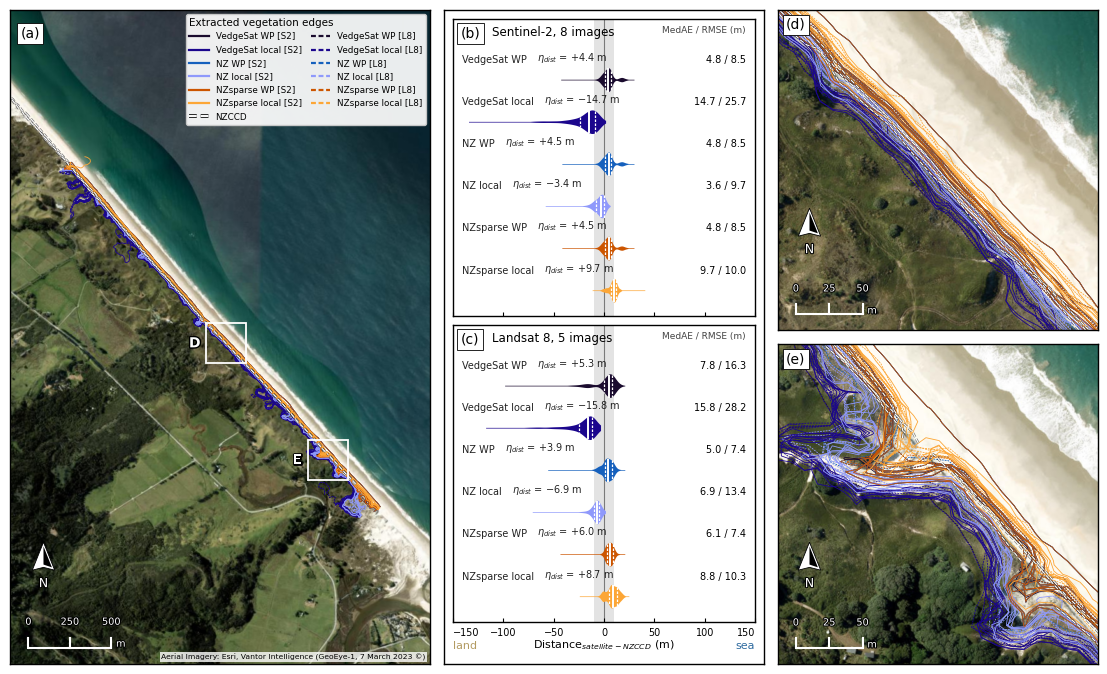

In [58]:
# ---------------- Pakiri (main foredune) ----------------
PAKIRI = dict(
    name='Pakiri', tag='BatchS', site='Pakiri',
    errors_csv=os.path.join(DATA, 'NZCCD_comparison_batch', 'errors_all.csv'),
    transects_dir=os.path.join(DATA, 'NZCCD_comparison_batch'),
    nzccd={d: os.path.join(NZCCD_DIR, f'NZCCD_Pakiri_{d.replace("-", "_")}.shp')
           for d in ['2017-02-03', '2021-10-14', '2023-04-04']},
    # map: every scenario on both satellites (colour = scenario, solid = S2, dotted = L8). To show fewer, add e.g.
    # map_scenarios=['default_WP', 'NZ_WP'] or map_sats=['S2']
    zooms=[('frac', 0.5, 85, -85), ('frac', 0.06, -60, 30)],  # ('frac', f, metres east, metres north): (d) mid-beach,
                                                   # straight lines; (e) the landward hook and the winding stretch
    zoom_line='2023-04-04',                        # NZCCD line whose transects position the close-ups
    zoom_half=120,                                 # m, half-width of each close-up
    zoom_window=15,                                # transects averaged for 'best' / 'worst'
    lw_map=0.6, lw_zoom=0.6,                       # line widths in (a) and in the close-ups
    zoom_map='auto', zoom_closeup=18,              # basemap tile zoom: at Pakiri, levels up to 18 are Esri's Vantor GeoEye-1
                                                   # image of 7 Mar 2023; 19 switches to LINZ's 2012 Auckland orthophotos
    attribution='Aerial Imagery: Esri, Vantor Intelligence (GeoEye-1, 7 March 2023 ©)',
    scale_map_m=500, scale_zoom_m=50,              # scale bar lengths (m) in (a) and in the close-ups
    pad=300,                                       # m around the edges in (a)
    violin_xlim=150,                               # m either side of NZCCD in the violins
)
site_figure(PAKIRI)

## Pakiri sparse-vegetation zone
One image per satellite (2023), so a different figure: **(a)** a map zoomed to the edges and the sparse-zone NZCCD line (no close-ups); **(b)** one chart of the probability densities of the transect distances for every scenario on both satellites (colour = scenario, solid = Sentinel-2, dashed = Landsat 8, as on the map), as in Muir et al. (2024, Figs 6–9). Each median (η<sub>dist</sub>) is a dotted line in the curve's colour and is given in the key. The cell also prints the median, MedAE and RMSE of every scenario.

Run the main functions cell above first, then the sparse functions cell, then the figure cell.

In [56]:
# ---------------- Functions: Pakiri sparse-zone figure (run after the main functions cell) ----------------
# Uses the shared map code from the cell above; everything about the distance chart is here.

def sparse_pdf_panel(ax, frame, cfg, E, letter='b'):
    """Probability densities of the transect distances for every scenario on both satellites in one chart
    (as Muir et al. 2024, Figs 6-9): colour = scenario, solid = Sentinel-2, dashed = Landsat 8, as on the map.
    Each curve's median (eta) is a full-height vertical line in the curve's own colour and line style (solid =
    Sentinel-2, dashed = Landsat 8), drawn behind the curves.
    ax = the plot (grey, no outline); frame = the bordered panel around it. The panel's white margin holds the
    letter, heading and key above the plot and the axis beneath it; the plot is fitted to the space left."""
    fig = ax.figure
    xl = cfg.get('pdf_xlim', 200)
    ax.set_facecolor(cfg.get('pdf_fill', '#efefef'))                  # light grey plot area, as Muir et al.
    for b, c in zip(sorted(cfg.get('pdf_bands', [WITHIN]), reverse=True), ['#d9d9d9', '#c8c8c8', '#b8b8b8']):
        ax.axvspan(-b, b, color=c, zorder=0, lw=0)
    ax.axvline(0, color='#7a7a7a', lw=0.8, zorder=1)
    xs = np.linspace(-xl, xl, 1000)
    order = cfg.get('draw_order') or SCEN_ORDER
    order = [k for k in SCEN_ORDER if k not in order] + list(order)       # bottom -> top
    sats = [s for s in ['S2', 'L8'] if (E.satname == s).any()]
    stats, top, z = {}, 0, 0
    for k in order:
        for sat in ['L8', 'S2']:                                         # Sentinel-2 over Landsat 8
            if sat not in sats:
                continue
            e = E[(E.satname == sat) & (E.run == SCEN_RUN[k])].error_m.values
            z += 1
            if len(e) < 2 or np.std(e) == 0:
                continue
            kde = mlab.GaussianKDE(e, 'scott')
            dens = kde.evaluate(xs)
            top = max(top, dens.max())
            ax.plot(xs, dens, color=SCEN_COLOUR[k], lw=cfg.get('lw_pdf', 1.1), ls=SAT_LS[sat], zorder=3 + z * 0.01)
            med = np.median(e)
            ax.axvline(med, color=SCEN_COLOUR[k], ls=SAT_LS[sat], lw=cfg.get('lw_median', 1.3),   # median: full
                       zorder=2 + z * 0.01, solid_capstyle='butt')               # height, styled like its curve
            stats[(k, sat)] = (med, np.median(np.abs(e)), np.sqrt(np.mean(e ** 2)), len(e),
                               int(np.sum(np.abs(e) > xl)))
    # identical results hide one another: say so
    for sat in sats:
        for i, k1 in enumerate(SCEN_ORDER):
            for k2 in SCEN_ORDER[i + 1:]:
                e1 = np.sort(E[(E.satname == sat) & (E.run == SCEN_RUN[k1])].error_m.values)
                e2 = np.sort(E[(E.satname == sat) & (E.run == SCEN_RUN[k2])].error_m.values)
                if len(e1) and len(e1) == len(e2) and np.allclose(e1, e2):
                    print(f'  Note: {SCEN_SHORT[k1]} and {SCEN_SHORT[k2]} [{sat}] have identical distances, so one '
                          f'curve lies exactly on the other')

    # key in the white margin above the plot: one column per satellite, a header over each
    handles, labels, headers = [], [], []
    for sat in sats:
        headers.append(len(labels))
        handles.append(Line2D([], [], lw=0)); labels.append(SAT_NAME[sat])
        for k in SCEN_ORDER:
            handles.append(Line2D([], [], color=SCEN_COLOUR[k], lw=1.4, ls=SAT_LS[sat]))
            st = stats.get((k, sat))
            labels.append(f'{SCEN_SHORT[k]}: ' + (f'{signed(st[0])} m' if st else 'no edge'))
            if st:
                print(f'  {sat} {SCEN_SHORT[k]:>15}: median {st[0]:+6.1f} m, MedAE {st[1]:5.1f} m, RMSE {st[2]:5.1f} m, '
                      f'{st[3]} transects' + (f', {st[4]} beyond \u00b1{xl} m (off the chart)' if st[4] else ''))
    fh = frame.get_position().height * fig.get_figheight()               # panel height, inches
    head_in = cfg.get('chart_top_space', 0.42)                           # inches for the letter and heading
    top_y = 1 - 0.5 * head_in / fh
    leg = frame.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1 - head_in / fh),
                       ncol=len(sats), fontsize=cfg.get('key_fontsize', 6.8), frameon=False, handlelength=2.4,
                       columnspacing=1.6, labelspacing=0.35, borderpad=0.2,
                       title=f'Median distance, {ETA}', title_fontsize=cfg.get('key_fontsize', 6.8) + 0.7)
    for i in headers:
        leg.get_texts()[i].set_fontweight('bold')
    n = E[['satname', 'date']].drop_duplicates().groupby('satname').size()
    if len(set(n.reindex(sats).fillna(0))) == 1:
        k = int(n.reindex(sats).fillna(0).iloc[0])
        head = f"{' and '.join(SAT_NAME[s] for s in sats)}, {k} image{'s' if k != 1 else ''} each"
    else:
        head = ', '.join(f"{SAT_NAME[s]} {n.get(s, 0)} image{'s' if n.get(s, 0) != 1 else ''}" for s in sats)
    frame.text(0.5, top_y, head, transform=frame.transAxes, fontsize=8.5, ha='center', va='center')
    frame.text(0.025, top_y, f'({letter})', transform=frame.transAxes, ha='left', va='center', fontsize=10,
               bbox=dict(fc='white', ec='black', lw=0.6, boxstyle='square,pad=0.25'))
    # fit the plot between the key and the axis labels
    try:
        bb = leg.get_window_extent(fig.canvas.get_renderer())
        key_bottom = bb.y0 / fig.bbox.height                                  # figure fraction
    except Exception:
        key_bottom = frame.get_position().y1 - (head_in + 1.3) / fig.get_figheight()
    pos = ax.get_position()
    y1 = key_bottom - cfg.get('key_gap', 0.1) / fig.get_figheight()
    ax.set_position([pos.x0, pos.y0, pos.width, y1 - pos.y0])
    ax.set_ylim(0, (top or 1) * cfg.get('pdf_headroom', 1.04))      # curves use (almost) the full height
    ax.set_yticks([])
    sparse_distance_axis(ax, xl, cfg.get('pdf_step'))


def sparse_distance_axis(ax, xl, step=None):
    """x axis from -xl to xl m, labelled below the chart: ticks every step m (default: 25 / 50 / 100 / 200 m,
    the smallest giving at most 7 labels), the ends only labelled when they fall on a tick; land / sea at the
    ends of the axis title's line."""
    ax.set_xlim(-xl, xl)
    step = step or next(s for s in (25, 50, 100, 200, 500) if 2 * (xl // s) + 1 <= 7)
    ticks = np.arange(-(xl // step) * step, xl + 1e-9, step)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t:g}'.replace('-', '\u2212') for t in ticks], fontsize=7)
    ax.tick_params(axis='x', direction='out', length=3, pad=2)
    for sp in ax.spines.values():                   # no outline: the grey fill sets the plot apart
        sp.set_visible(False)
    lab = ax.set_xlabel('Distance$_{satellite - NZCCD}$ (m)', fontsize=8, labelpad=3)
    for x, t, c, ha in [(0, 'land', '#b39b62', 'left'), (1, 'sea', '#2d6a9f', 'right')]:
        ax.annotate(t, xy=(x, 0.5), xycoords=('axes fraction', lab), color=c, fontsize=8, ha=ha, va='center')


def sparse_figure(cfg):
    """(a) map of a small area, zoomed to the edges and the NZCCD line, beside (b) one chart of the distance
    densities for both satellites: a grey plot inside a bordered panel, letter and heading above it and the axis
    below it in the panel's white margin (as Muir et al. 2024). No close-ups."""
    E, layers, nz_gdfs, nz_col = load_inputs(cfg)
    S, g = cfg.get('panel', 3.2), cfg.get('gap', 0.14)
    ml, mb, mt, mr = 0.06, 0.06, 0.06, 0.06
    H = 2 * S + g
    # extent: every edge and the NZCCD line plus pad; the map is as wide as that shape needs at height H
    if cfg.get('extent_latlon'):
        x0, x1, y0, y1 = site_extent(cfg, layers, None)
    else:
        b = [L['geom'].bounds for L in layers if L['geom'] is not None and not L['geom'].is_empty]
        b += [tuple(gdf.total_bounds) for gdf in nz_gdfs.values()]
        b = np.array(b); pad = cfg.get('pad', 40)
        x0, x1, y0, y1 = b[:, 0].min() - pad, b[:, 2].max() + pad, b[:, 1].min() - pad, b[:, 3].max() + pad
    Wa = cfg.get('map_width') or float(np.clip(H * (x1 - x0) / (y1 - y0), 2.6, 7.0))
    Wb = cfg.get('chart_width', 3.6)
    W, FH = ml + Wa + g + Wb + mr, mb + H + mt
    fig = plt.figure(figsize=(W, FH))
    box = lambda x, y, w, h: fig.add_axes([x / W, y / FH, w / W, h / FH])
    axA = box(ml, mb, Wa, H)
    xb = ml + Wa + g
    frame = box(xb, mb, Wb, H)                       # border of panel (b)
    frame.set_xticks([]); frame.set_yticks([])
    for sp in frame.spines.values():
        sp.set_linewidth(1)
    pt = cfg.get('chart_top_space', 0.42)            # inches of white above the key (letter and heading); the plot
                                                     # is then fitted below the key
    pb = cfg.get('chart_label_space', 0.45)          # inches of white below it (tick labels and axis title)
    side = cfg.get('chart_side_space', 0.12)         # inches of white either side
    axB = box(xb + side, mb + pb, Wb - 2 * side, H - pt - pb)

    map_extent(axA, x0, x1, y0, y1, zoom=cfg.get('zoom_map', 'auto'))
    draw_lines(axA, layers, nz_gdfs, nz_col, lw=cfg.get('lw_map', 0.9), order=cfg.get('draw_order'))
    finish_map(axA, cfg, layers)
    if cfg.get('check_imagery', True):
        xa, xc = axA.get_xlim(); ya, yc = axA.get_ylim()
        imagery_sources((xa + xc) / 2, (ya + yc) / 2, '(a) centre')
    sparse_pdf_panel(axB, frame, cfg, E)
    save_figure(fig, cfg)

Pakiri sparse zone: reading edges...
  12 edges; drawing the maps (downloading the aerial can take a minute)...
Esri imagery at (a) centre (-36.2400, 174.7213):
    30cm: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    60cm: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    1.2m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    2.4m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    4.8m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
  Note: VedgeSat WP and NZ WP [S2] have identical distances, so one curve lies exactly on the other
  S2     VedgeSat WP: median  -85.4 m, MedAE  85.4 m, RMSE  89.0 m, 40 transects
  S2  VedgeSat local: median -131.0 m, MedAE 131.0 m, RMSE 121.7 m, 26 transects
  S2           NZ WP: median  -85.4 m, MedAE  85.4 m, RMSE  89.0 m, 40 transects
  S2        NZ l

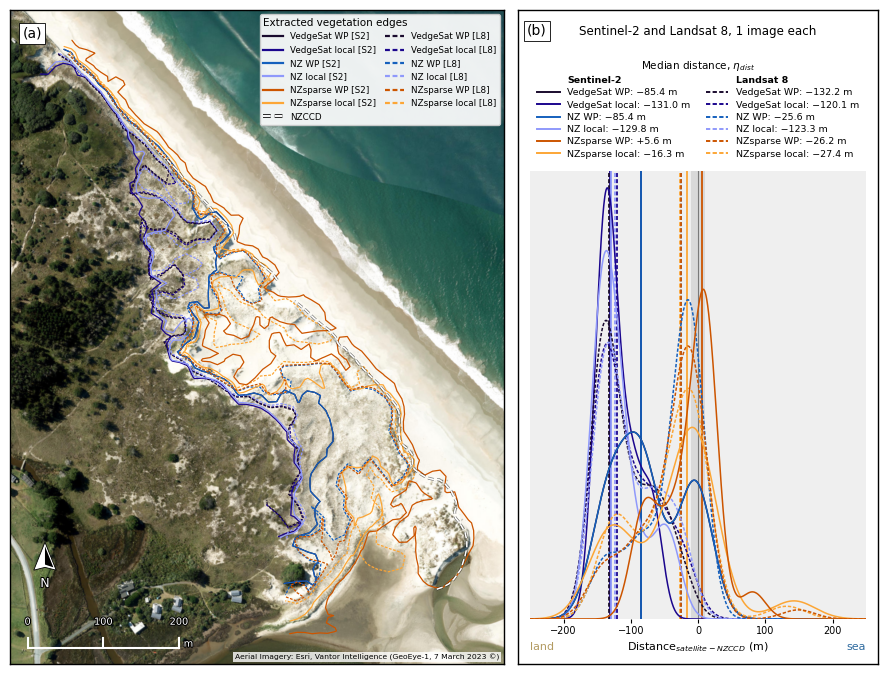

In [57]:
# ---------------- Pakiri sparse-vegetation zone (one image per satellite) ----------------
PAKIRI_SPARSE = dict(
    name='Pakiri sparse zone', tag='BatchS', site='PakiriSparse',
    errors_csv=os.path.join(DATA, 'Extra_analyses', 'NZCCD_comparison_PakiriSparse', 'errors_all.csv'),
    transects_dir=os.path.join(DATA, 'Extra_analyses', 'NZCCD_comparison_PakiriSparse'),
    nzccd={'2023-04-04': os.path.join(NZCCD_DIR, 'pakiri_sparse', 'pakiri_sparse_nzccd.shp')},
    pad=40,                                        # m around the edges and the NZCCD line: the map's extent
    scale_map_m=200,                               # scale bar length (m): 0 / 100 / 200
    legend_loc='upper right',                      # key position on the map, e.g. 'lower right' if it covers lines
    lw_map=0.9,                                    # line width on the map
    # line layering, bottom -> top (Landsat 8 under Sentinel-2 within each): NZsparse on top here
    draw_order=['default_local', 'default_WP', 'NZ_local', 'NZ_WP', 'NZsparse_local', 'NZsparse_WP'],
    zoom_map=18,                                   # 18 = Esri's GeoEye-1 image of 7 Mar 2023 (19 would switch to the 2012 orthos)
    attribution='Aerial Imagery: Esri, Vantor Intelligence (GeoEye-1, 7 March 2023 ©)',
    pdf_xlim=250,                                  # m either side of NZCCD in (b): change to 250, 300... for a wider chart
    pdf_step=None,                                 # tick spacing (m); None = automatic (50 m up to ±300 m)
    pdf_bands=[10],                                # shaded distances (m); [10, 15] also shades the Landsat pixel size, as Muir et al.
    lw_pdf=1.1, lw_median=1.3,                     # line widths of the density curves and the dotted median lines
    chart_width=3.6,                               # inches, width of panel (b)
)
sparse_figure(PAKIRI_SPARSE)

## Muriwai

Muriwai: reading edges...
  84 edges; drawing the maps (downloading the aerial can take a minute)...
Close-up (d): best: median |error| 9.7 m (transect 151), shifted -420 m E, +725 m N; NZTM 1725994, 5926134; 610 x 1100 m
Close-up (e): 0.00 of the way south to north (transect 354), shifted +0 m E, +200 m N; NZTM 1727264, 5923237; 480 x 640 m
Esri imagery at (a) centre (-36.8120, 174.4169):
    30cm: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    60cm: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    1.2m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    2.4m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
    4.8m: 20240131  Auckland Council / Auckland Council 2024 / Auckland Council Orthos, 0.075 m
Esri imagery at close-up (d) (-36.8023, 174.4124):
    30cm: 20240131  Auckland Council / Auckland Council 2024 / Auckland Coun

TimeoutError: [Errno 60] Operation timed out

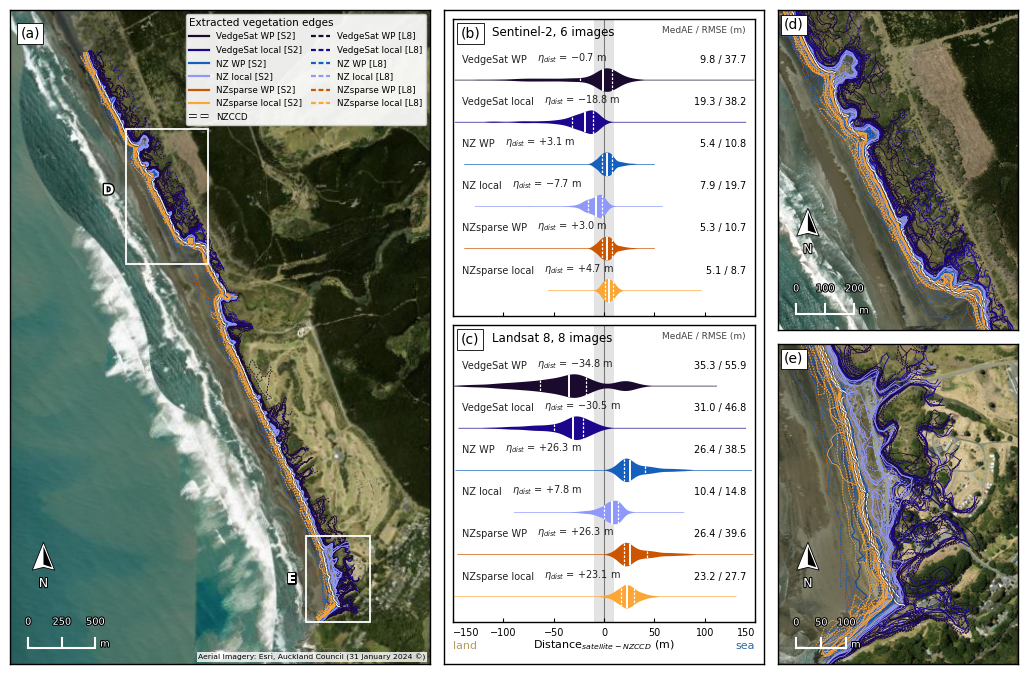

In [59]:
# ---------------- Muriwai ----------------
MURIWAI = dict(
    name='Muriwai', tag='BatchS', site='Muriwai',
    errors_csv=os.path.join(DATA, 'NZCCD_comparison_batch', 'errors_all.csv'),
    transects_dir=os.path.join(DATA, 'NZCCD_comparison_batch'),
    nzccd={d: os.path.join(NZCCD_DIR, f'NZCCD_Muriwai_{d.replace("-", "_")}.shp')
           for d in ['2017-07-15', '2020-01-25', '2022-01-17']},
    # (d) from the 'drumstick' near the top of the beach down to the stream outlet (shifted from the 'best' stretch);
    # (e) the south end with the car park. For exact placement use ('latlon', lat, lon) read off Google Earth.
    zooms=[('best', -420, 725), ('frac', 0.0, 0, 200)],
    zoom_size=[(610, 1100), (480, 640)],           # (width, height) m of each close-up: portrait
    map_box_trim=[(0, 0, 0, 90), None],            # (left, right, bottom, top) m off the D box drawn in (a), clear of the legend
    zoom_line='2022-01-17', zoom_window=15,
    lw_map=0.6, lw_zoom=0.6,                       # line widths in (a) and in the close-ups
    # line layering, bottom -> top (Landsat 8 under Sentinel-2 within each); NZsparse local on top, then NZ, VedgeSat WP over local
    draw_order=['NZsparse_WP', 'default_local', 'default_WP', 'NZ_local', 'NZ_WP', 'NZsparse_local'],
    scale_map_m=500, scale_zoom_m=[200, 100],      # scale bar lengths (m) in (a), (d) and (e)
    zoom_map='auto', zoom_closeup=18,              # basemap tile zoom; the cell prints which image each panel uses
    attribution='Aerial Imagery: Esri, Auckland Council (31 January 2024 ©)',   # Auckland Council 2024 orthophotos, 0.075 m
    pad=300, violin_xlim=150,
)
site_figure(MURIWAI)